<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving mobile_prices.csv to mobile_prices.csv
MOBILE PRICE DATASET:
    RAM_GB  Storage_GB  Battery_mAh  Camera_MP  Screen_Size_Inches  \
0        2          32         3000         12                 6.0   
1        3          32         3500         13                 6.1   
2        4          64         4000         16                 6.2   
3        4         128         4200         16                 6.3   
4        6         128         4500         48                 6.4   
5        6         128         5000         50                 6.5   
6        8         128         4500         50                 6.6   
7        8         256         5000         64                 6.7   
8        8         256         4800         64                 6.8   
9       12         256         5000         64                 6.9   
10      12         256         5200        108                 6.9   
11      12         512         5000        108                 6.9   
12      16         512

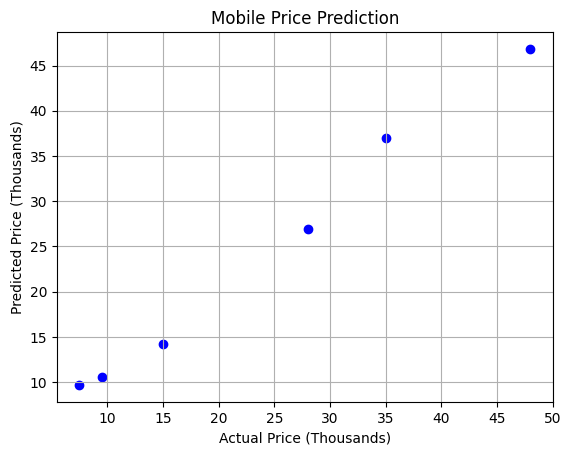

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))

data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("MOBILE PRICE DATASET:")
print(data)

# Input and output
X = data.drop("Price_Thousands", axis=1)
y = data["Price_Thousands"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Create Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("\nActual Mobile Prices:")
print(y_test.values)

print("\nPredicted Mobile Prices:")
print(y_pred)

print("\nMean Absolute Error:")
print(mean_absolute_error(y_test, y_pred))

print("\nMean Squared Error:")
print(mean_squared_error(y_test, y_pred))

print("\nR2 Score:")
print(r2_score(y_test, y_pred))

# Predict new mobile price
new_mobile = pd.DataFrame({
    "RAM_GB": [8],
    "Storage_GB": [128],
    "Battery_mAh": [5000],
    "Camera_MP": [50],
    "Screen_Size_Inches": [6.5]
})

price = model.predict(new_mobile)

print("\nPredicted Mobile Price:")
print("Rs.", round(price[0] * 1000, 2))

# Plot graph
plt.scatter(y_test, y_pred, color="blue")

plt.xlabel("Actual Price (Thousands)")
plt.ylabel("Predicted Price (Thousands)")
plt.title("Mobile Price Prediction")

plt.grid()
plt.show()